In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df=pd.read_csv('/content/drive/MyDrive/iris.csv')

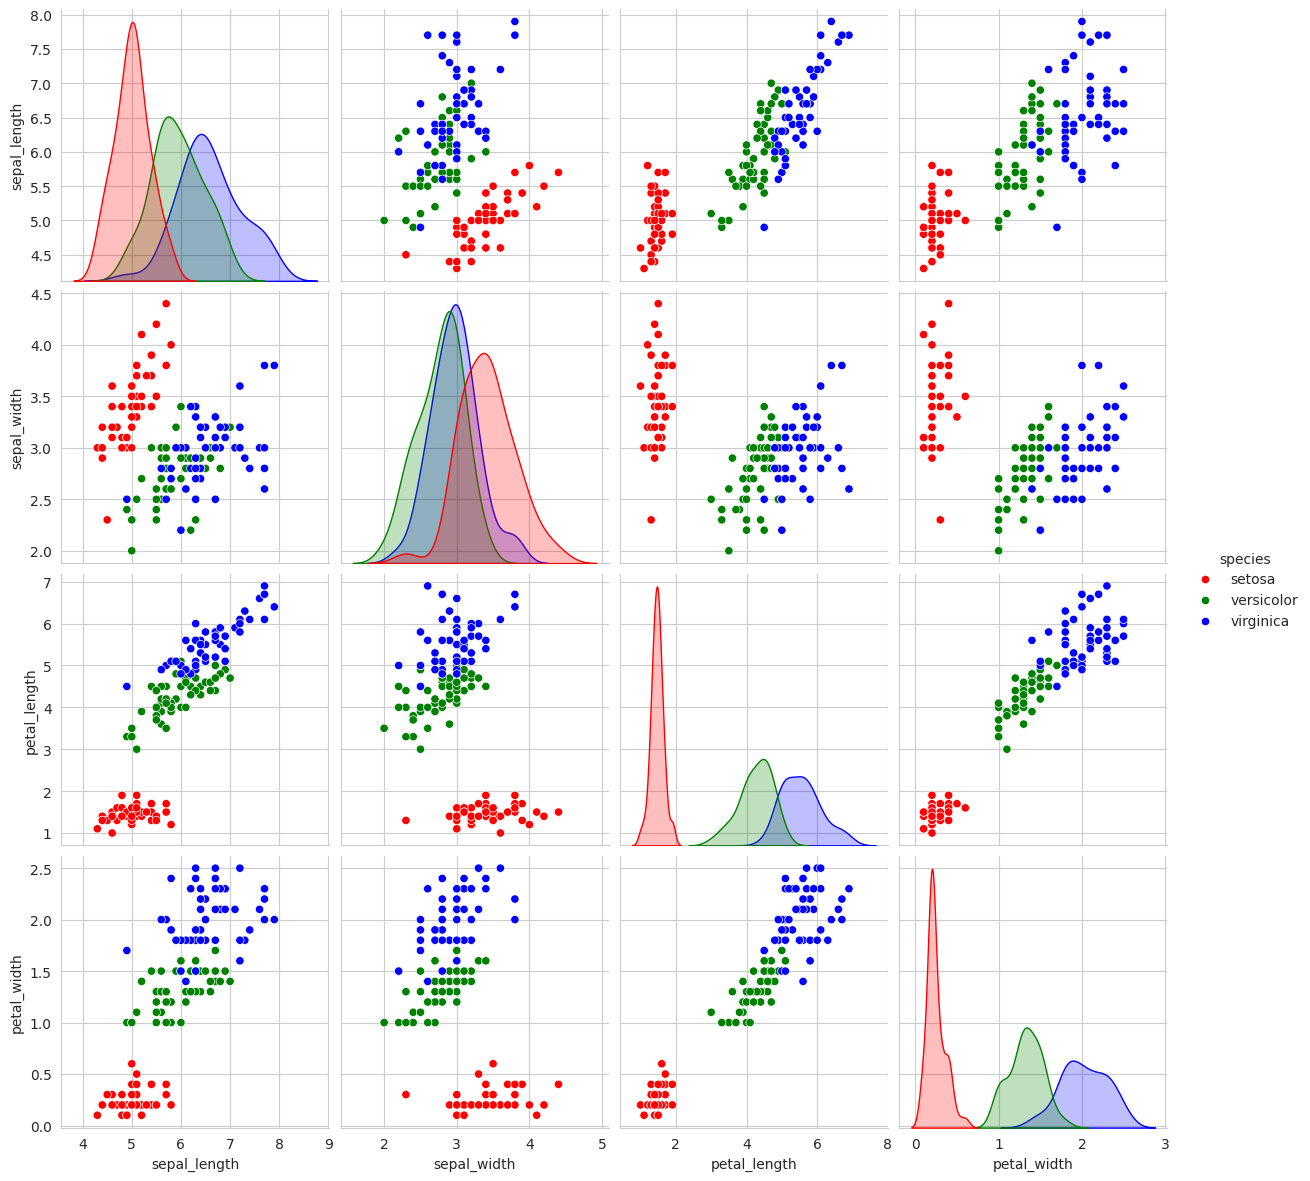

In [ ]:
plt.close();
sns.set_style("whitegrid");
palette={
    "setosa":"red",
    "versicolor":"green",
    "virginica":"blue"
}

sns.pairplot(df,hue="species",palette=palette,height=3);
plt.show();

In [ ]:
print(df.shape)

(150, 5)


print(df.head())

In [ ]:
print(df.head())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [ ]:
print(df.tail())

     sepal_length  sepal_width  petal_length  petal_width    species
145           6.7          3.0           5.2          2.3  virginica
146           6.3          2.5           5.0          1.9  virginica
147           6.5          3.0           5.2          2.0  virginica
148           6.2          3.4           5.4          2.3  virginica
149           5.9          3.0           5.1          1.8  virginica


In [ ]:
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [ ]:
print(df.species)

0         setosa
1         setosa
2         setosa
3         setosa
4         setosa
         ...    
145    virginica
146    virginica
147    virginica
148    virginica
149    virginica
Name: species, Length: 150, dtype: object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [ ]:
from sklearn import preprocessing
le=preprocessing.LabelEncoder()
le.fit(df.species)
df['species']=le.transform(df.species)
print(df)

     sepal_length  sepal_width  petal_length  petal_width  species
0             5.1          3.5           1.4          0.2        0
1             4.9          3.0           1.4          0.2        0
2             4.7          3.2           1.3          0.2        0
3             4.6          3.1           1.5          0.2        0
4             5.0          3.6           1.4          0.2        0
..            ...          ...           ...          ...      ...
145           6.7          3.0           5.2          2.3        2
146           6.3          2.5           5.0          1.9        2
147           6.5          3.0           5.2          2.0        2
148           6.2          3.4           5.4          2.3        2
149           5.9          3.0           5.1          1.8        2

[150 rows x 5 columns]


In [ ]:
print(df.species)

0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Name: species, Length: 150, dtype: int64


In [ ]:
X=df.iloc[:,0:4]

In [ ]:
X

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [ ]:
y=df.iloc[:,4]

In [ ]:
y


,species
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


In [ ]:
x_train, x_test, y_train, y_test=train_test_split(X, y, train_size=0.70, random_state=42)

In [ ]:
print(x_train.shape)

(105, 4)


In [ ]:
print(x_test.shape)

(45, 4)


In [ ]:
print(y_train.shape)

(105,)


In [ ]:
print(y_test.shape)

(45,)


In [ ]:
x_train

,sepal_length,sepal_width,petal_length,petal_width
81,5.5,2.4,3.7,1.0
133,6.3,2.8,5.1,1.5
137,6.4,3.1,5.5,1.8
75,6.6,3.0,4.4,1.4
109,7.2,3.6,6.1,2.5
...,...,...,...,...
71,6.1,2.8,4.0,1.3
106,4.9,2.5,4.5,1.7
14,5.8,4.0,1.2,0.2
92,5.8,2.6,4.0,1.2


In [ ]:
y_train

,species
81,1
133,2
137,2
75,1
109,2
...,...
71,1
106,2
14,0
92,1


In [ ]:
model1=SVC(C=.1,kernel='linear',gamma=1)

In [ ]:
model1

SVC(C=0.1, gamma=1, kernel='linear')

In [ ]:
model_train1=model1.fit(x_train,y_train)

In [ ]:
model_train1

SVC(C=0.1, gamma=1, kernel='linear')

In [ ]:
y_pred1=model_train1.predict(x_test)

In [ ]:
y_pred1

array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0, 0, 0, 1, 0, 0, 2, 1, 0, 0, 0, 2, 1, 1, 0,
       0])

In [ ]:
y_pred1[0:10]

array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1])

In [ ]:
print(y_test[:10])

73     1
18     0
118    2
78     1
76     1
31     0
64     1
141    2
68     1
82     1
Name: species, dtype: int64


In [ ]:
i=0
print("\n----------------------------------------------------------------------------------------------")
print('%-25s %-25s %25s' % ('Orginial Label','Predicted Label','Correct/Wrong'))
print("------------------------------------------------------------------------------------------------")
for label in y_test:
  print('%-25s %-25s' % (label,y_pred1[i]), end="")
  if(label==y_pred1[i]):
    print('%-25s' % ('Correct'))
  else:
    print('%-25s' %('Wrong'))
  i=i+1
print("\n----------------------------------------------------------------------------------------------")


----------------------------------------------------------------------------------------------
Orginial Label            Predicted Label                       Correct/Wrong
------------------------------------------------------------------------------------------------
1                         1                        Correct                  
0                         0                        Correct                  
2                         2                        Correct                  
1                         1                        Correct                  
1                         1                        Correct                  
0                         0                        Correct                  
1                         1                        Correct                  
2                         2                        Correct                  
1                         1                        Correct                  
1                         1         

In [ ]:
import sklearn.metrics as metrics
confusion=metrics.confusion_matrix(y_test,y_pred1)
confusion

array([[19,  0,  0],
       [ 0, 13,  0],
       [ 0,  0, 13]])

In [ ]:
accuracy=accuracy_score(y_test,y_pred1)

In [ ]:
accuracy

1.0

In [ ]:
print('Accuracy of the classifier is  %0.2f' % metrics.accuracy_score(y_test,y_pred1))
print("-------------------------------------------------------------------------------------------")

Accuracy of the classifier is  1.00
-------------------------------------------------------------------------------------------


In [ ]:
print("\nClassification Report:\n",)
class_wise=metrics.classification_report(y_test,y_pred1)
print(class_wise)


Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



In [ ]:
new_sample=[[5.1,3.5,1.4,0.2]]
prediction=model1.predict(new_sample)
predicted_label=le.inverse_transform(prediction)
print("Predicted Class=",predicted_label)

Predicted Class= ['setosa']


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


In [ ]:
model2=SVC()

In [ ]:
model2

SVC()

In [ ]:
model_train2=model2.fit(x_train,y_train)

In [ ]:
model_train2

SVC()

In [ ]:
y_pred2=model_train2.predict(x_test)

In [ ]:
y_pred2


array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0, 0, 0, 1, 0, 0, 2, 1, 0, 0, 0, 2, 1, 1, 0,
       0])

In [ ]:
i=0
print("\n----------------------------------------------------------------------------------------------")
print('%-25s %-25s %25s' % ('Orginial Label','Predicted Label','Correct/Wrong'))
print("------------------------------------------------------------------------------------------------")
for label in y_test:
  print('%-25s %-25s' % (label,y_pred2[i]), end="")
  if(label==y_pred2[i]):
    print('%-25s' % ('Correct'))
  else:
    print('%-25s' %('Wrong'))
  i=i+1
print("\n----------------------------------------------------------------------------------------------")


----------------------------------------------------------------------------------------------
Orginial Label            Predicted Label                       Correct/Wrong
------------------------------------------------------------------------------------------------
1                         1                        Correct                  
0                         0                        Correct                  
2                         2                        Correct                  
1                         1                        Correct                  
1                         1                        Correct                  
0                         0                        Correct                  
1                         1                        Correct                  
2                         2                        Correct                  
1                         1                        Correct                  
1                         1         

In [ ]:
import sklearn.metrics as metrics
confusion=metrics.confusion_matrix(y_test,y_pred2)
confusion

array([[19,  0,  0],
       [ 0, 13,  0],
       [ 0,  0, 13]])

In [ ]:
accuracy=accuracy_score(y_test,y_pred2)

In [ ]:
accuracy


1.0

In [ ]:
print('Accuracy of the classifier is  %0.2f' % metrics.accuracy_score(y_test,y_pred2))
print("-------------------------------------------------------------------------------------------")

Accuracy of the classifier is  1.00
-------------------------------------------------------------------------------------------


In [ ]:
print("\nClassification Report:\n",)
class_wise=metrics.classification_report(y_test,y_pred2)
print(class_wise)


Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



In [ ]:
model3=SVC(kernel='poly')

In [ ]:
model3

SVC(kernel='poly')

In [ ]:
model_train3=model3.fit(x_train,y_train)

In [ ]:
model_train3

SVC(kernel='poly')

In [ ]:
y_pred3=model_train3.predict(x_test)

In [ ]:
y_pred3

array([1, 0, 2, 1, 1, 0, 1, 2, 2, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0, 0, 0, 1, 0, 0, 2, 1, 0, 0, 0, 2, 1, 1, 0,
       0])

In [ ]:
i=0
print("\n----------------------------------------------------------------------------------------------")
print('%-25s %-25s %25s' % ('Orginial Label','Predicted Label','Correct/Wrong'))
print("------------------------------------------------------------------------------------------------")
for label in y_test:
  print('%-25s %-25s' % (label,y_pred3[i]), end="")
  if(label==y_pred3[i]):
    print('%-25s' % ('Correct'))
  else:
    print('%-25s' %('Wrong'))
  i=i+1
print("\n----------------------------------------------------------------------------------------------")


----------------------------------------------------------------------------------------------
Orginial Label            Predicted Label                       Correct/Wrong
------------------------------------------------------------------------------------------------
1                         1                        Correct                  
0                         0                        Correct                  
2                         2                        Correct                  
1                         1                        Correct                  
1                         1                        Correct                  
0                         0                        Correct                  
1                         1                        Correct                  
2                         2                        Correct                  
1                         2                        Wrong                    
1                         1         

In [ ]:
import sklearn.metrics as metrics
confusion=metrics.confusion_matrix(y_test,y_pred3)
confusion

array([[19,  0,  0],
       [ 0, 12,  1],
       [ 0,  0, 13]])

In [ ]:
accuracy=accuracy_score(y_test,y_pred3)

In [ ]:
accuracy


0.9777777777777777

In [ ]:
print('Accuracy of the classifier is  %0.2f' % metrics.accuracy_score(y_test,y_pred3))
print("-------------------------------------------------------------------------------------------")

Accuracy of the classifier is  0.98
-------------------------------------------------------------------------------------------


In [ ]:
print("\nClassification Report:\n",)
class_wise=metrics.classification_report(y_test,y_pred3)
print(class_wise)


Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      0.92      0.96        13
           2       0.93      1.00      0.96        13

    accuracy                           0.98        45
   macro avg       0.98      0.97      0.97        45
weighted avg       0.98      0.98      0.98        45

